# NB-06 — Era clássica: segmentação e casamento de modelos (Cap. 2, §2.2)

> **Demonstração didática.** Base Washington (GW20, CIIR/UMass, uso não comercial, não redistribuir): 20 páginas, treino em CPU, vocabulário fechado. Os números **não** são comparáveis com a literatura nem com o BRESSAY; servem para mostrar o mecanismo de cada família do Cap. 2. Dados em `notebooks/dados/washington/` (fora do git; ver `lib/gw_demo.py`).

Mostra (1) segmentação de linhas por **perfil de projeção**, (2) reconhecimento holístico por **casamento de modelos** (1-vizinho mais próximo sobre pixels), sem aprendizado de representação, (3) o mesmo reconhecimento sobre **características manuais** (HOG, filtros de Gabor e momentos de Hu), com 1-NN e SVM, e (4) a **transição** para as redes convolucionais: o LeNet-5 no MNIST, base de dígitos diferente da Washington.

In [1]:
# Parâmetros
from pathlib import Path
SAIDA = Path('saidas/NB-06')
SEED = 0


In [2]:
import sys
sys.path.insert(0, '.')
import numpy as np, matplotlib.pyplot as plt
from lib import gw_demo as gw, gw_modelos as m
SAIDA.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
tr, va, te = m.carregar(gw.TREINO), m.carregar(gw.VALID), m.carregar(gw.TESTE)
print(f'palavras: treino {len(tr[0])} (páginas 0-13) | validação {len(va[0])} | teste {len(te[0])} (páginas 17-19)')

palavras: treino 3439 (páginas 0-13) | validação 684 | teste 707 (páginas 17-19)


## 1. Segmentação de linhas por perfil de projeção horizontal
Soma-se a tinta de cada linha de pixels; os vales do perfil separam as linhas de texto (Seção 2.1.2).

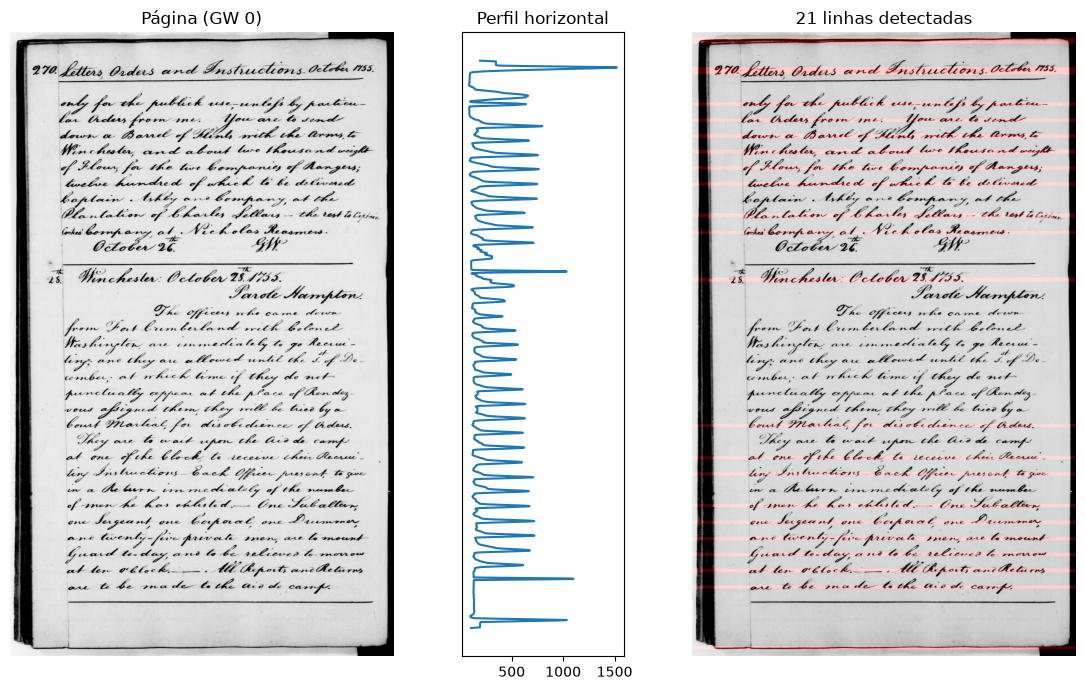

In [3]:
pag = gw.abrir_pagina(0)
b, perfil, linhas = m.segmentar_linhas(pag)
fig, ax = plt.subplots(1, 3, figsize=(12, 7), gridspec_kw={'width_ratios': [3, 1, 3]})
ax[0].imshow(pag, cmap='gray'); ax[0].set_title('Página (GW 0)'); ax[0].axis('off')
ax[1].plot(perfil, np.arange(len(perfil))); ax[1].invert_yaxis(); ax[1].set_title('Perfil horizontal'); ax[1].set_yticks([])
vis = np.stack([pag]*3, -1).copy()
for y0, y1 in linhas: vis[y0:y1, :, 0] = np.clip(vis[y0:y1, :, 0].astype(int) + 70, 0, 255)
ax[2].imshow(vis); ax[2].set_title(f'{len(linhas)} linhas detectadas'); ax[2].axis('off')
plt.tight_layout(); plt.savefig(SAIDA/'segmentacao_linhas.png', dpi=130); plt.show()

## 2. Casamento de modelos (1-NN) sobre palavras
Cada palavra de teste recebe o rótulo da imagem de treino mais parecida (distância euclidiana). Não há treino: só memória.

In [4]:
VOC = m.top_palavras(tr[1], k=20, minimo=8)       # vocabulário fechado: as 20 palavras mais frequentes
Xtr, ytr = m.filtrar(*tr, VOC); Xva, yva = m.filtrar(*va, VOC); Xte, yte = m.filtrar(*te, VOC)
ytr, yva, yte = map(np.array, (ytr, yva, yte))
print(VOC); print('amostras:', len(Xtr), len(Xva), len(Xte))

['the', 'to', 'and', 'of', 'you', 'are', 'be', 'for', 'that', 'i', 'as', 'with', 'in', 'at', 'is', 'your', 'a', 'they', 'will', 'which']
amostras: 1176 213 252


In [5]:
f = lambda X: np.stack([m.fixa(i) for i in X]).reshape(len(X), -1)
pred = m.vizinho_mais_proximo(f(Xtr), ytr, f(Xte))
acc = (pred == yte).mean()
print(f'Acurácia 1-NN (palavra inteira, {len(VOC)} classes): {acc:.3f}  (acaso ≈ {1/len(VOC):.3f})')

Acurácia 1-NN (palavra inteira, 20 classes): 0.746  (acaso ≈ 0.050)


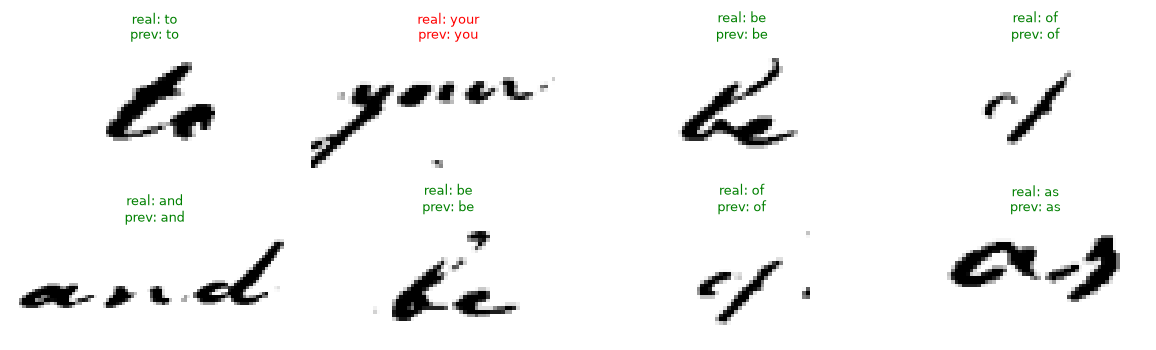

In [6]:
# Exemplos de acertos e erros
idx = np.random.default_rng(SEED).choice(len(Xte), 8, replace=False)
fig, ax = plt.subplots(2, 4, figsize=(12, 3.6))
for a, i in zip(ax.ravel(), idx):
    a.imshow(Xte[i], cmap='gray_r'); a.axis('off')
    ok = pred[i] == yte[i]
    a.set_title(f'real: {VOC[yte[i]]}\nprev: {VOC[pred[i]]}', color='green' if ok else 'red', fontsize=9)
plt.tight_layout(); plt.savefig(SAIDA/'exemplos_1nn.png', dpi=130); plt.show()

## 3. Características manuais
Na era clássica, o classificador não recebia a imagem, e sim um vetor de números calculado por uma regra projetada à mão e fixa (Cap. 2, §2.2). Três exemplos:
- **HOG** (histograma de gradientes orientados): em cada célula de 8×8 pixels, conta para que lado apontam as bordas do traço (9 faixas de ângulo, ponderadas pela intensidade da borda) e normaliza grupos de 2×2 células. Descreve a forma do traço.
- **Filtros de Gabor**: ondas senoidais sob uma gaussiana, sintonizadas em 4 orientações (0°, 45°, 90°, 135°; no OpenCV o ângulo é o da onda, de modo que o filtro de 0° realça os traços verticais e o de 90°, os horizontais); guarda-se a energia média de cada orientação numa grade de 4×12 regiões. Descreve a direção dominante dos traços em cada parte da palavra.
- **Momentos de Hu**: 7 combinações dos momentos da imagem que não mudam com translação, escala ou rotação, mais a proporção largura/altura da palavra. Resumem a forma global em 8 números.

Nenhum desses números é aprendido; quem decide o que é relevante é o projetista. É exatamente o que as redes convolucionais (NB-08) passam a aprender a partir dos dados.

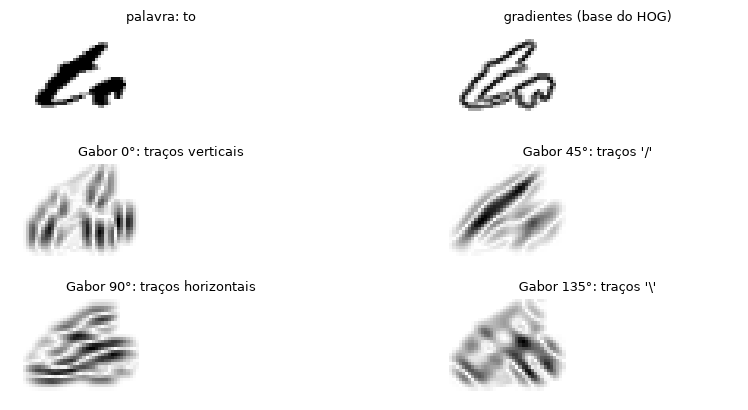

In [7]:
# O que cada característica "vê" numa palavra de teste
x = m.fixa(Xte[idx[0]])
mag, _ = m.gradientes(x)
paineis = [(x, f'palavra: {VOC[yte[idx[0]]]}'), (mag, 'gradientes (base do HOG)')]
# no OpenCV, o ângulo é o da onda: o filtro de 0° realça traços verticais
TRACO = {0: 'traços verticais', 45: "traços '/'", 90: 'traços horizontais', 135: "traços '\\'"}
paineis += [(r, f'Gabor {t}°: {TRACO[t]}') for r, t in zip(m.respostas_gabor(x), m.GABOR_ANGULOS)]
fig, ax = plt.subplots(3, 2, figsize=(9, 4.2))
for a, (img, tit) in zip(ax.ravel(), paineis):
    a.imshow(img, cmap='gray_r'); a.set_title(tit, fontsize=9); a.axis('off')
plt.tight_layout(); plt.savefig(SAIDA/'caracteristicas_manuais.png', dpi=130); plt.show()

In [8]:
# Mesmas palavras, mesmos classificadores, representações diferentes
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

REPR = {
    'pixels': lambda i: m.fixa(i).ravel(),
    'HOG': lambda i: m.hog(m.fixa(i)),
    'Gabor': lambda i: m.gabor(m.fixa(i)),
    'Hu + proporção': lambda i: m.hu(m.fixa(i), i.shape[1] / i.shape[0]),
}
linhas = []
for nome, f in REPR.items():
    A, B = np.stack([f(i) for i in Xtr]), np.stack([f(i) for i in Xte])
    knn = (m.vizinho_mais_proximo(A, ytr, B) == yte).mean()
    svm = make_pipeline(StandardScaler(), SVC(C=10, gamma='scale')).fit(A, ytr).score(B, yte)
    linhas.append({'representação': nome, 'dimensão': A.shape[1], '1-NN': round(knn, 3), 'SVM (RBF)': round(svm, 3)})
tab = pd.DataFrame(linhas)
tab.to_csv(SAIDA/'caracteristicas_manuais.csv', index=False)
print(f'Acurácia no teste ({len(yte)} palavras, {len(VOC)} classes; acaso ≈ {1/len(VOC):.3f}); SVM com C=10 fixo, sem ajuste na validação')
tab

Acurácia no teste (252 palavras, 20 classes; acaso ≈ 0.050); SVM com C=10 fixo, sem ajuste na validação


,representação,dimensão,1-NN,SVM (RBF)
0,pixels,3072,0.746,0.694
1,HOG,1188,0.790,0.802
2,Gabor,192,0.853,0.889
3,Hu + proporção,8,0.504,0.655


**Leitura:** o casamento de modelos funciona razoavelmente em vocabulário fechado e com o mesmo escritor (Washington é de um só punho), mas não generaliza para palavras fora do vocabulário nem para outros estilos, e a segmentação por projeção falha com linhas inclinadas ou que se tocam. É a limitação que motiva as famílias seguintes.

Com características manuais, o mesmo 1-NN sobe de 0,746 (pixels) para 0,790 (HOG) e 0,853 (Gabor), e o SVM chega a 0,889 com Gabor, usando 192 números em vez de 3.072. Já os momentos de Hu, compactos demais, caem para 0,504: quando a representação descarta a informação, nenhum classificador a recupera. A qualidade dependia, portanto, de quem projetava as características, e essa é a etapa que as redes convolucionais automatizam.

## 4. Transição: LeNet-5 no MNIST (LeCun et al., 1998)

> **Nota: esta seção é de transição, não da era clássica.** O LeNet-5 (`lecun1998`, Cap. 2, l. 187) ainda segue a lógica da era clássica num ponto: classifica **um símbolo isolado e já segmentado** (um dígito por imagem), como o 1-NN e o SVM acima. A diferença está na representação. As características deixam de ser projetadas à mão (HOG, Gabor, Hu) e passam a ser **aprendidas** pelas convoluções, a partir dos dados. Ele é a ponte entre a seção 3 deste notebook e as redes convolucionais da Seção 2.5, demonstradas no NB-08.

**Outra base.** O LeNet-5 foi proposto para o MNIST, e aqui ele roda no MNIST, não na Washington: 60.000 dígitos de treino e 10.000 de teste, 28×28 pixels, escritos por centenas de pessoas (LeCun, Cortes e Burges; licença CC BY-SA 3.0). O download é feito uma vez para `notebooks/dados/mnist/` (fora do git), com conferência de MD5 (`lib/mnist.py`). Por isso, os números desta seção **não** se comparam com os das seções 2 e 3: a tarefa é outra (10 dígitos, muitos escritores, muito mais dados).

**Arquitetura** (entrada 32×32, o dígito de 28×28 com borda de 2 pixels, como no artigo):
C1 (6 filtros 5×5) → S2 (subamostragem 2×2) → C3 (16 filtros 5×5) → S4 (subamostragem 2×2) → C5 (120 filtros 5×5) → F6 (84 unidades) → saída (10 dígitos), com tangente hiperbólica entre as camadas.

**Três simplificações** em relação ao artigo, comuns nas reimplementações: (a) a C3 liga cada mapa a todos os 6 mapas da S2 (o artigo usa uma tabela de conexões parcial); (b) a subamostragem é a média simples (no artigo, a média tem coeficiente e viés treináveis); (c) a saída é uma camada linear com entropia cruzada, treinada com Adam (no artigo, unidades RBF e outro procedimento de treino). Para referência, o artigo relata 0,95% de erro no teste para o LeNet-5 sem distorções nos dados de treino; o valor daqui é só uma ordem de grandeza.

Como linha de base, o mesmo 1-NN da seção 2 (casamento de modelos sobre pixels), agora no MNIST.

MNIST: treino 60000, teste 10000, imagens 28x28


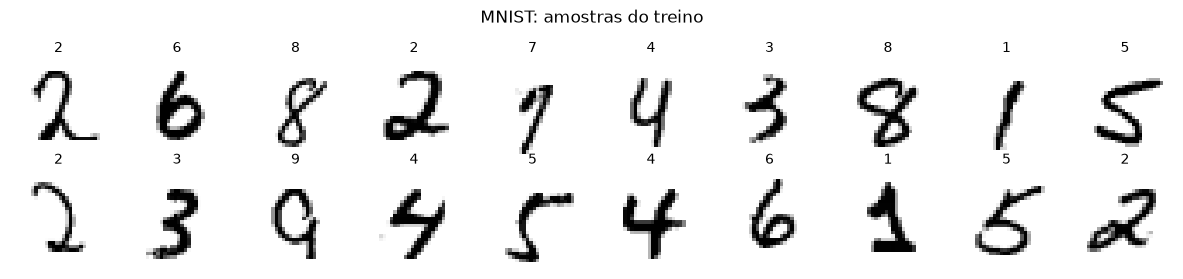

1-NN sobre pixels: erro no teste 3.09%


In [9]:
from lib import mnist as mn
Mtr, mtr, Mte, mte = mn.carregar()
print(f'MNIST: treino {len(Mtr)}, teste {len(Mte)}, imagens {Mtr.shape[1]}x{Mtr.shape[2]}')
fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))
for a, i in zip(ax.ravel(), np.random.default_rng(SEED).choice(len(Mtr), 20, replace=False)):
    a.imshow(Mtr[i], cmap='gray_r'); a.set_title(str(mtr[i]), fontsize=10); a.axis('off')
plt.suptitle('MNIST: amostras do treino'); plt.tight_layout(); plt.savefig(SAIDA/'mnist_amostras.png', dpi=150); plt.show()

# Linha de base: casamento de modelos (1-NN euclidiano sobre pixels), sem aprendizado
pred_1nn = mn.vizinho_mais_proximo(Mtr / 255.0, mtr, Mte / 255.0)
erro_1nn = 1 - (pred_1nn == mte).mean()
print(f'1-NN sobre pixels: erro no teste {100 * erro_1nn:.2f}%')

In [10]:
# LeNet-5: as características são aprendidas pelas convoluções
import torch
torch.manual_seed(SEED)
lenet = mn.lenet5()
n_par = sum(p.numel() for p in lenet.parameters())
print(f'LeNet-5: {n_par} parâmetros treináveis')
EPOCAS = 15  # número fixo: o teste só acompanha a curva, não escolhe a época
hist = mn.treinar(lenet, mn.para_lenet(Mtr), mtr, mn.para_lenet(Mte), mte, epocas=EPOCAS, seed=SEED)
pred_lenet = mn.prever(lenet, mn.para_lenet(Mte))
erro_lenet = 1 - (pred_lenet == mte).mean()

import pandas as pd
tab_mnist = pd.DataFrame([
    {'método': '1-NN sobre pixels (casamento de modelos)', 'características': 'nenhuma (pixels)', 'parâmetros treinados': 0, 'erro no teste (%)': round(100 * erro_1nn, 2)},
    {'método': f'LeNet-5 ({EPOCAS} épocas)', 'características': 'aprendidas (convolução)', 'parâmetros treinados': n_par, 'erro no teste (%)': round(100 * erro_lenet, 2)},
])
tab_mnist.to_csv(SAIDA/'lenet5_mnist.csv', index=False)
pd.DataFrame(hist, columns=['época', 'perda no treino', 'erro no teste']).to_csv(SAIDA/'lenet5_curva.csv', index=False)
tab_mnist

LeNet-5: 61706 parâmetros treináveis


época  1  perda 0.4055  erro no teste 4.28%


época  2  perda 0.1224  erro no teste 2.79%


época  3  perda 0.0791  erro no teste 2.08%


época  4  perda 0.0580  erro no teste 1.66%


época  5  perda 0.0470  erro no teste 1.48%


... (7 outputs left out)

época 13  perda 0.0125  erro no teste 1.22%


época 14  perda 0.0103  erro no teste 1.25%


época 15  perda 0.0091  erro no teste 1.32%


,método,características,parâmetros treinados,erro no teste (%)
0,1-NN sobre pixels (casamento de modelos),nenhuma (pixels),0,3.09
1,LeNet-5 (15 épocas),aprendidas (convolução),61706,1.32


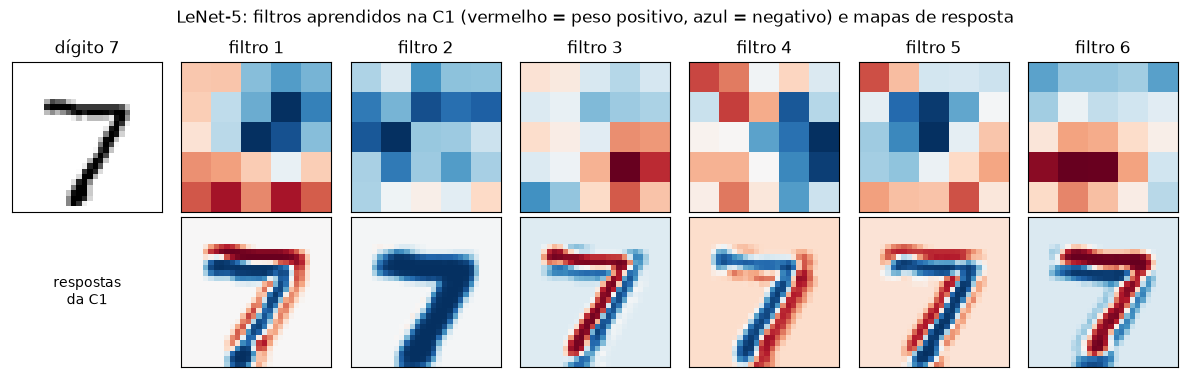

In [11]:
# O que a primeira camada aprendeu: os 6 filtros 5x5 da C1 e as respostas a um dígito.
# Compare com os filtros de Gabor da seção 3, que foram escolhidos à mão.
filtros = lenet[0].weight.detach().numpy()[:, 0]
x = torch.as_tensor(mn.para_lenet(Mte[:1]))
with torch.no_grad():
    mapas = lenet[1](lenet[0](x))[0].numpy()
fig, ax = plt.subplots(2, 7, figsize=(12, 3.8))
ax[0, 0].imshow(Mte[0], cmap='gray_r'); ax[0, 0].set_title(f'dígito {mte[0]}')
ax[1, 0].axis('off'); ax[1, 0].text(0.5, 0.5, 'respostas\nda C1', ha='center', va='center')
for k in range(6):
    lim = np.abs(filtros[k]).max()
    ax[0, k + 1].imshow(filtros[k], cmap='RdBu_r', vmin=-lim, vmax=lim); ax[0, k + 1].set_title(f'filtro {k + 1}')
    ax[1, k + 1].imshow(mapas[k], cmap='RdBu_r', vmin=-1, vmax=1)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.suptitle('LeNet-5: filtros aprendidos na C1 (vermelho = peso positivo, azul = negativo) e mapas de resposta')
plt.tight_layout(); plt.savefig(SAIDA/'lenet5_filtros_c1.png', dpi=150); plt.show()

132 erros em 10000 dígitos de teste


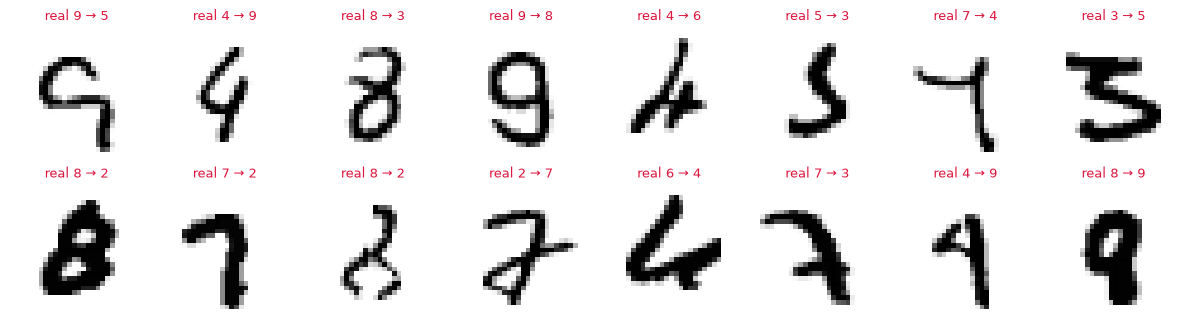

In [12]:
# Onde o LeNet-5 ainda erra
erros = np.flatnonzero(pred_lenet != mte)
print(f'{len(erros)} erros em {len(mte)} dígitos de teste')
fig, ax = plt.subplots(2, 8, figsize=(12, 3.4))
for a, i in zip(ax.ravel(), erros[:16]):
    a.imshow(Mte[i], cmap='gray_r'); a.axis('off')
    a.set_title(f'real {mte[i]} → {pred_lenet[i]}', fontsize=9, color='crimson')
plt.tight_layout(); plt.savefig(SAIDA/'lenet5_erros.png', dpi=150); plt.show()

**Leitura:** no MNIST, o LeNet-5 erra 1,32% dos dígitos de teste (132 de 10.000), contra 3,09% do 1-NN sobre pixels: menos da metade dos erros. Além disso, o 1-NN precisa guardar as 60.000 imagens de treino (cerca de 47 milhões de números) e compará-las com cada dígito novo, enquanto o LeNet-5 resume o que aprendeu em 61.706 parâmetros.

A figura dos filtros mostra o centro da transição. Os seis filtros 5×5 da C1 não foram projetados por ninguém, mas se parecem com detectores de borda em orientações diferentes (horizontal no filtro 6, diagonais nos filtros 3 e 4), a mesma ideia dos gradientes do HOG e dos filtros de Gabor da seção 3. A diferença é que aqui a regra saiu dos dados, e as camadas seguintes (C3, C5) combinam essas bordas em padrões maiores, sem que alguém precise decidir quais.

Duas ressalvas. (1) O erro fica acima dos 0,95% do artigo, o que é esperado com as simplificações descritas acima e com só 15 épocas sem ajuste. Da época 9 em diante, o erro oscila entre 1,18% e 1,41%, então a segunda casa decimal não é significativa. (2) O LeNet-5 ainda depende de o dígito chegar **isolado e segmentado**. Reconhecer uma linha manuscrita inteira, sem segmentar os caracteres, exige modelar a sequência, o que só vem com as famílias seguintes (NB-07 a NB-10).